# CropGuard AI — Deep Learning Fundamentals
## Notebook 01: Artificial Neurons, Activations & Multilayer Perceptrons (MLP)

**Course Alignment:** UPES Deep Learning Course Plan (CSAI3027P) — **Unit I: Fundamentals & Unit II: Tensors & Operations**

> **Welcome to CropGuard AI!**
> This notebook is designed for interactive, step-by-step learning. You can run each cell individually to see intermediate computations, inspect variables, and view generated visualizations.
> 
> **Kernel:** `Python 3.14 (CropGuard AI .venv)` with NVIDIA GeForce RTX 5060 GPU acceleration.

---
### Table of Contents
0. [Environment & GPU Verification](#topic-0)
1. [Introduction to Artificial Neurons](#topic-1)
2. [McCulloch-Pitts (M-P) Neuron (1943)](#topic-2)
3. [Weighted Sum and Threshold (Rosenblatt Perceptron)](#topic-3)
4. [Sigmoid Neuron and Its Graph](#topic-4)
5. [Activation Functions & Comprehensive Comparison](#topic-5)
6. [Parameters vs. Hyperparameters](#topic-6)
7. [Multilayer Perceptron (MLP) & The XOR Problem](#topic-7)
8. [Feed-Forward Neural Networks in TensorFlow / Keras](#topic-8)
9. [Complete Classification Example & Training Curves](#topic-9)

---
<a id='topic-0'></a>
## 0. Environment Setup & Hardware Verification

Before diving into the mathematics, let us verify our imports and ensure our hardware acceleration (GPU) is ready.

In [12]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print(f"Python Version    : {sys.version.split()[0]}")
print(f"NumPy Version     : {np.__version__}")
print(f"TensorFlow Version: {tf.__version__}")

# Check GPU Availability
gpus = tf.config.list_physical_devices('GPU')
print(f"GPUs Available    : {len(gpus)}")
for i, gpu in enumerate(gpus):
    print(f"  - GPU {i}: {gpu.name}")

# Enable memory growth to allow efficient VRAM allocation
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU Memory Growth : Enabled")
    except RuntimeError as e:
        print(f"Notice: {e}")
else:
    print("Running on CPU mode.")

Python Version    : 3.14.4
NumPy Version     : 2.5.4
TensorFlow Version: 2.22.0-rc0
GPUs Available    : 1
  - GPU 0: /physical_device:GPU:0
GPU Memory Growth : Enabled


---
<a id='topic-1'></a>
## 1. Introduction to Artificial Neurons

### A. Markdown Explanation
An **Artificial Neuron** (or Perceptron) is the fundamental atomic building block of all deep learning architectures.

In biological neural networks:
* **Dendrites** receive incoming electrochemical impulses from neighboring neurons.
* The **Cell Body (Soma)** accumulates and sums the signals.
* The **Axon** fires an output spike if the accumulated potential surpasses an action threshold.

In artificial neural networks, we mathematically model this process:
1. Receive numerical inputs $x_1, x_2, \dots, x_n$.
2. Scale each input by a learnable **weight** $w_i$, indicating the importance of that input.
3. Add a learnable **bias** $b$, which shifts the decision threshold.
4. Apply an **activation function** $f(\cdot)$ to produce the final output $y$.

### B. Mathematical Formula
The linear combination (often called the **net input** or **pre-activation** $z$):
$$\text{net} = z = \sum_{i=1}^{n} w_i x_i + b = \mathbf{w}^T \mathbf{x} + b$$

The neuron output after activation:
$$y = f(z) = f(\mathbf{w}^T \mathbf{x} + b)$$

### C. Simple Practical Example
Imagine an agricultural diagnostic assistant evaluating an apple leaf image:
* Feature $x_1$: Rust spot density (e.g., $0.8$ on a scale of 0 to 1).
* Feature $x_2$: Yellowing percentage (e.g., $0.6$ on a scale of 0 to 1).
* Assigned weights: $w_1 = 2.0$, $w_2 = 1.5$.
* Bias: $b = -1.2$ (threshold to avoid false alarms).

Let us calculate the net input $z$ and observe intermediate values step-by-step.

In [13]:
# Inputs: Spot density and Yellowing degree
x = np.array([0.8, 0.6])

# Weights corresponding to each feature
w = np.array([2.0, 1.5])

# Bias term
b = -1.2

# Step 1: Element-wise multiplication (x_i * w_i)
weighted_inputs = x * w

# Step 2: Sum of weighted inputs (dot product)
dot_product = np.dot(w, x)  # or np.sum(weighted_inputs)

# Step 3: Add bias to obtain pre-activation z
z = dot_product + b

print("=== Manual Neuron Calculation ===")
print(f"Inputs (x)          : {x}")
print(f"Weights (w)         : {w}")
print(f"Bias (b)            : {b}")
print(f"Weighted inputs     : {weighted_inputs}  (0.8*2.0={weighted_inputs[0]:.2f}, 0.6*1.5={weighted_inputs[1]:.2f})")
print(f"Sum of weights*x    : {dot_product:.2f}")
print(f"Net input (z = w·x+b): {z:.2f}")

=== Manual Neuron Calculation ===
Inputs (x)          : [0.8 0.6]
Weights (w)         : [2.  1.5]
Bias (b)            : -1.2
Weighted inputs     : [1.6 0.9]  (0.8*2.0=1.60, 0.6*1.5=0.90)
Sum of weights*x    : 2.50
Net input (z = w·x+b): 1.30


### E. Expected Output
When you run the code cell above, you will see:
* `Weighted inputs: [1.6, 0.9]`
* `Sum of weights*x: 2.50`
* `Net input (z = w·x+b): 1.30`

### F. Short Interpretation
Because the net score $z = 1.30$ is strictly positive ($> 0$), the combined evidence from spot density and yellowing is strong enough to cross the baseline threshold set by bias $b = -1.2$. If passed through a binary step threshold, this neuron fires ($y = 1$), signaling potential leaf disease.

### G. Viva Questions
1. **Q:** What is the mathematical and biological role of the bias term $b$ in an artificial neuron?
   * **Answer:** Biologically, bias represents the intrinsic threshold excitability of the soma. Mathematically, bias provides an affine translation (intercept) that allows the decision boundary to shift freely without being constrained to pass through the coordinate origin $(0, 0)$.
2. **Q:** Why can an artificial neuron with only linear operations ($\sum w_i x_i + b$) not model complex real-world data?
   * **Answer:** A linear combination of linear functions is always strictly linear. Without non-linear activation functions, a network of any depth collapses mathematically into a single linear regression model, unable to learn curved boundaries or hierarchical features.

---
<a id='topic-2'></a>
## 2. McCulloch-Pitts (M-P) Neuron (1943)

### A. Markdown Explanation
Introduced by neurophysiologist Warren McCulloch and logician Walter Pitts in 1943, the **M-P Neuron** was the very first computational model of a biological neuron.

Key characteristics of an M-P neuron:
1. **Strictly Binary Inputs and Outputs:** Inputs $x_i \in \{0, 1\}$ and output $y \in \{0, 1\}$.
2. **Two Input Types:**
   * *Excitatory inputs:* contribute equally towards triggering the neuron ($w_i = +1$).
   * *Inhibitory inputs:* have veto power. If any inhibitory input is active ($1$), the neuron is completely suppressed from firing ($y = 0$).
3. **Fixed Threshold $\theta$:** The neuron fires if and only if the sum of excitatory inputs equals or exceeds an integer threshold $\theta$.
4. **No Learning Algorithm:** Weights are fixed and non-trainable; human engineers must hand-craft $\theta$.

### B. Mathematical Formula
For $n$ excitatory inputs $x_1, x_2, \dots, x_n$ with no active inhibitory inputs:
$$g(x_1, x_2, \dots, x_n) = \sum_{i=1}^{n} x_i$$

$$y = \begin{cases} 1 & \text{if } \sum_{i=1}^{n} x_i \ge \theta \\ 0 & \text{if } \sum_{i=1}^{n} x_i < \theta \end{cases}$$

### C. Simple Practical Example: Logic Gates
We can build fundamental Boolean logic gates using an M-P neuron:
* **AND Gate ($x_1 \text{ AND } x_2$):** Fires only when *both* inputs are $1$. Threshold $\theta = 2$.
* **OR Gate ($x_1 \text{ OR } x_2$):** Fires when *at least one* input is $1$. Threshold $\theta = 1$.

In [14]:
def mcculloch_pitts_neuron(inputs, threshold, inhibitory=False):
    """
    McCulloch-Pitts Neuron implementation.
    :param inputs: list or array of binary values (0 or 1)
    :param threshold: integer threshold theta
    :param inhibitory: boolean flag (if True, vetoes the firing)
    :return: 1 if fired, else 0
    """
    if inhibitory:
        return 0
    
    # Calculate sum of excitatory inputs
    total_excitation = np.sum(inputs)
    return 1 if total_excitation >= threshold else 0

# All combinations of two binary inputs
input_combinations = [[0, 0], [0, 1], [1, 0], [1, 1]]

print("=== McCulloch-Pitts Logic Gates ===")
print("x1  x2 | AND (θ=2) | OR (θ=1)")
print("----------------------------")
for x1, x2 in input_combinations:
    y_and = mcculloch_pitts_neuron([x1, x2], threshold=2)
    y_or  = mcculloch_pitts_neuron([x1, x2], threshold=1)
    print(f"{x1}   {x2}  |     {y_and}     |    {y_or}")

=== McCulloch-Pitts Logic Gates ===
x1  x2 | AND (θ=2) | OR (θ=1)
----------------------------
0   0  |     0     |    0
0   1  |     0     |    1
1   0  |     0     |    1
1   1  |     1     |    1


### E. Expected Output
The code prints the standard truth tables for AND and OR gates:
* AND gate outputs $1$ only for $[1, 1]$.
* OR gate outputs $1$ for $[0, 1]$, $[1, 0]$, and $[1, 1]$.

### F. Short Interpretation
The M-P neuron showed that simple binary units can perform logical operations. However, because its weights are fixed ($1$) and cannot be updated automatically from data, it cannot perform supervised learning or adapt to continuous signals.

### G. Viva Questions
1. **Q:** What is the primary historical limitation of the McCulloch-Pitts neuron?
   * **Answer:** It lacks a learning mechanism. Weights are fixed unit values ($1$ or $-\infty$) and the threshold $\theta$ must be manually designed by an engineer rather than learned through gradient descent or error-correction.
2. **Q:** Can a single McCulloch-Pitts neuron represent the XOR function?
   * **Answer:** No. XOR is not linearly separable. An M-P neuron can only form a single flat decision boundary and cannot isolate the diagonal points $[0, 1]$ and $[1, 0]$ from $[0, 0]$ and $[1, 1]$.

---
<a id='topic-3'></a>
## 3. Weighted Sum and Threshold (Rosenblatt Perceptron)

### A. Markdown Explanation
In 1958, Frank Rosenblatt created the **Perceptron**. This was a revolutionary breakthrough because it introduced:
1. **Continuous Real-Valued Weights ($w_i \in \mathbb{R}$):** Inputs can have varying positive or negative influences.
2. **Continuous Real-Valued Inputs ($x_i \in \mathbb{R}$):** Real-world measurements (sensor values, pixel intensities).
3. **Learnable Parameters:** Weights can be adjusted automatically via the **Perceptron Learning Rule** based on training errors.

In a 2D feature space $(x_1, x_2)$, the decision boundary is a straight line where the pre-activation equals zero:
$$w_1 x_1 + w_2 x_2 + b = 0 \implies x_2 = -\frac{w_1}{w_2} x_1 - \frac{b}{w_2}$$

### B. Mathematical Formula
Weighted linear sum:
$$z = \sum_{i=1}^{m} w_i x_i + b$$

Heaviside step activation function:
$$\hat{y} = \text{step}(z) = \begin{cases} 1 & \text{if } z \ge 0 \\ 0 & \text{if } z < 0 \end{cases}$$

### C. Simple Practical Example
Suppose we want to classify whether an apple leaf is healthy ($y=0$) or diseased ($y=1$) using:
* $x_1$: Chlorophyll absorbance index.
* $x_2$: Necrotic spot radius (mm).

Let us evaluate 4 leaf samples and plot the linear decision boundary separating the two classes.

Sample | x1 (Chlorophyll) | x2 (Necrosis) | Net Score (z) | Prediction (y_hat) | Ground Truth
-----------------------------------------------------------------------------------------
   0   |       1.2        |      0.5      |      -1.70    |         0          |      0
   1   |       2.0        |      1.0      |      -2.30    |         0          |      0
   2   |       0.5        |      3.2      |       2.59    |         1          |      1
   3   |       1.0        |      4.0      |       2.80    |         1          |      1


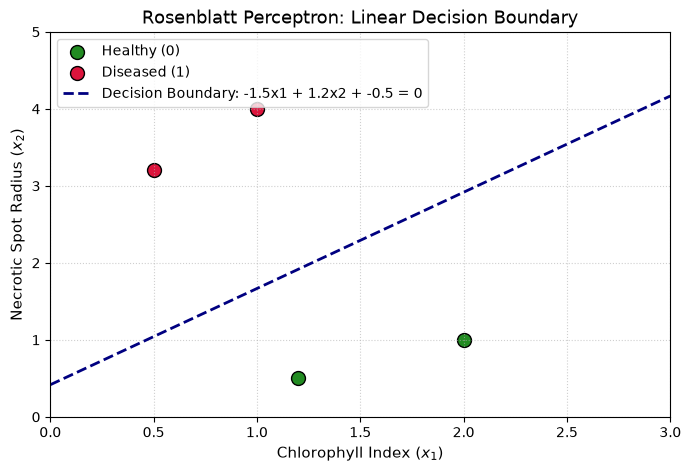

In [15]:
# Sample data: 4 leaf measurements [chlorophyll_index, necrotic_radius]
X_samples = np.array([
    [1.2, 0.5],   # Sample 0: Healthy
    [2.0, 1.0],   # Sample 1: Healthy
    [0.5, 3.2],   # Sample 2: Diseased
    [1.0, 4.0]    # Sample 3: Diseased
])
y_labels = np.array([0, 0, 1, 1])

# Pre-determined perceptron weights and bias
w1, w2 = -1.5, 1.2
b = -0.5

# Calculate net score z for each sample
z_scores = X_samples[:, 0] * w1 + X_samples[:, 1] * w2 + b
predictions = (z_scores >= 0).astype(int)

print("Sample | x1 (Chlorophyll) | x2 (Necrosis) | Net Score (z) | Prediction (y_hat) | Ground Truth")
print("-----------------------------------------------------------------------------------------")
for i in range(len(X_samples)):
    print(f"   {i}   |       {X_samples[i, 0]:.1f}        |      {X_samples[i, 1]:.1f}      |     {z_scores[i]:6.2f}    |         {predictions[i]}          |      {y_labels[i]}")

# Visualizing the Decision Boundary
plt.figure(figsize=(8, 5))
plt.scatter(X_samples[y_labels==0, 0], X_samples[y_labels==0, 1], color='forestgreen', s=100, label='Healthy (0)', edgecolor='black')
plt.scatter(X_samples[y_labels==1, 0], X_samples[y_labels==1, 1], color='crimson', s=100, label='Diseased (1)', edgecolor='black')

# Calculate decision boundary line: x2 = -(w1/w2)*x1 - (b/w2)
x1_line = np.linspace(0, 3, 100)
x2_line = -(w1 / w2) * x1_line - (b / w2)
plt.plot(x1_line, x2_line, color='navy', linestyle='--', linewidth=2, label=f'Decision Boundary: {w1}x1 + {w2}x2 + {b} = 0')

plt.title("Rosenblatt Perceptron: Linear Decision Boundary", fontsize=13)
plt.xlabel("Chlorophyll Index ($x_1$)", fontsize=11)
plt.ylabel("Necrotic Spot Radius ($x_2$)", fontsize=11)
plt.xlim(0, 3)
plt.ylim(0, 5)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### E. Expected Output
The cell displays a table of calculated $z$ scores and a 2D scatter plot showing healthy green points below the line and diseased red points above the dashed navy decision boundary line.

### F. Short Interpretation
The linear equation $w_1 x_1 + w_2 x_2 + b = 0$ cuts the feature plane into two distinct half-spaces. Any sample yielding $z > 0$ falls into class $1$, while $z < 0$ falls into class $0$.

### G. Viva Questions
1. **Q:** What geometric shape does the decision boundary of a single Perceptron form in an $n$-dimensional feature space?
   * **Answer:** An $(n-1)$-dimensional affine hyperplane (a point in 1D, a line in 2D, a flat plane in 3D, and a hyperplane in higher dimensions).
2. **Q:** Why can the step function not be trained with backpropagation or gradient descent?
   * **Answer:** The derivative of the Heaviside step function is zero everywhere, except at $z=0$ where it is discontinuous and undefined. Because the gradient is zero, weights cannot receive any directional feedback to update via gradient descent.

---
<a id='topic-4'></a>
## 4. Sigmoid Neuron and Its Graph

### A. Markdown Explanation
To enable gradient-based learning via calculus, we replace the rigid, non-differentiable step function with a smooth, continuous, S-shaped curve: the **Sigmoid (or Logistic) function** $\sigma(z)$.

Key mathematical properties of the Sigmoid function:
1. **Domain:** $(-\infty, \infty)$.
2. **Range:** $(0, 1)$, making it ideally suited for modeling probabilities: $\hat{y} = P(Y=1 | \mathbf{x})$.
3. **Smooth & Differentiable Everywhere:** Its derivative has a remarkably elegant and computationally cheap closed-form expression.
4. **Symmetry:** $\sigma(-z) = 1 - \sigma(z)$.

### B. Mathematical Formula
The Sigmoid function:
$$\sigma(z) = \frac{1}{1 + e^{-z}} = \frac{e^z}{e^z + 1}$$

Its first derivative with respect to $z$:
$$\frac{d\sigma(z)}{dz} = \sigma(z) \cdot (1 - \sigma(z))$$

### C. Simple Practical Example
Let us evaluate the sigmoid function across a spectrum of net input scores $z \in [-6, 6]$ and inspect how its derivative behaves.

  z   | Sigmoid σ(z) | Derivative σ'(z)
---------------------------------------
 -3.0 |    0.0474    |     0.0452
 -1.0 |    0.2689    |     0.1966
  0.0 |    0.5000    |     0.2500
  1.0 |    0.7311    |     0.1966
  3.0 |    0.9526    |     0.0452


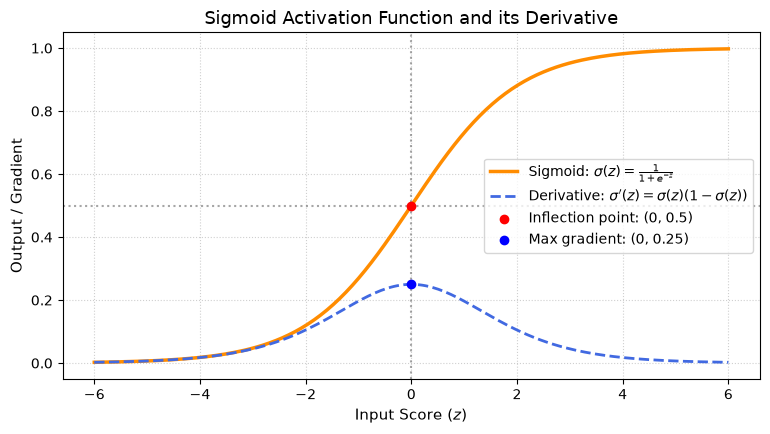

In [16]:
def sigmoid(z):
    """Standard logistic sigmoid function."""
    return 1.0 / (1.0 + np.exp(-z))

def sigmoid_derivative(z):
    """Derivative of sigmoid function: s * (1 - s)."""
    s = sigmoid(z)
    return s * (1.0 - s)

# Generate values for z from -6 to +6
z_vals = np.linspace(-6, 6, 200)
sig_vals = sigmoid(z_vals)
deriv_vals = sigmoid_derivative(z_vals)

# Specific sample evaluations
test_points = [-3.0, -1.0, 0.0, 1.0, 3.0]
print("  z   | Sigmoid σ(z) | Derivative σ'(z)")
print("---------------------------------------")
for p in test_points:
    print(f"{p:5.1f} |    {sigmoid(p):.4f}    |     {sigmoid_derivative(p):.4f}")

# Plot Sigmoid and its Derivative
plt.figure(figsize=(9, 4.5))
plt.plot(z_vals, sig_vals, color='darkorange', linewidth=2.5, label=r"Sigmoid: $\sigma(z) = \frac{1}{1 + e^{-z}}$")
plt.plot(z_vals, deriv_vals, color='royalblue', linewidth=2, linestyle='--', label=r"Derivative: $\sigma'(z) = \sigma(z)(1 - \sigma(z))$")

plt.axvline(0, color='gray', linestyle=':', alpha=0.7)
plt.axhline(0.5, color='gray', linestyle=':', alpha=0.7)
plt.scatter([0], [0.5], color='red', zorder=5, label='Inflection point: (0, 0.5)')
plt.scatter([0], [0.25], color='blue', zorder=5, label='Max gradient: (0, 0.25)')

plt.title("Sigmoid Activation Function and its Derivative", fontsize=13)
plt.xlabel("Input Score ($z$)", fontsize=11)
plt.ylabel("Output / Gradient", fontsize=11)
plt.ylim(-0.05, 1.05)
plt.legend(loc='center right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### E. Expected Output
The cell outputs a table and a dual-curve plot:
* The orange Sigmoid curve smoothly ascends from $0$ to $1$, crossing exactly at $(0, 0.5)$.
* The blue dashed derivative curve is a bell shape centered at $z=0$, peaking at $0.25$.

### F. Short Interpretation
Notice that when $|z|$ is large (e.g. $z > 4$ or $z < -4$), the Sigmoid curve flattens out, and the derivative drops close to $0$. This phenomenon is known as **gradient saturation**, which causes the **vanishing gradient problem** when backpropagating through deep networks.

### G. Viva Questions
1. **Q:** What is the maximum value of the derivative of the Sigmoid function, and where does it occur?
   * **Answer:** The maximum derivative is $\sigma'(0) = 0.5 \times (1 - 0.5) = 0.25$, which occurs precisely at $z = 0$.
2. **Q:** Why does a maximum derivative of $0.25$ contribute to the vanishing gradient problem in deep networks?
   * **Answer:** By the chain rule, gradients backpropagated through $L$ sigmoid layers are multiplied by factors of $\le 0.25$ at each layer. For example, through 5 layers: $(0.25)^5 \approx 0.00097$. The gradient shrinks exponentially, effectively halting weight updates in early layers.

---
<a id='topic-5'></a>
## 5. Activation Functions & Comprehensive Comparison

### A. Markdown Explanation
Different tasks and layer depths require different activation functions. Let us compare the 5 most important activation functions in modern deep learning:

| Function | Formula | Range | Key Advantages | Primary Use Case |
| :--- | :--- | :--- | :--- | :--- |
| **Sigmoid** | $\frac{1}{1 + e^{-z}}$ | $(0, 1)$ | Probabilistic interpretation | Binary classification output layer |
| **Tanh** | $\frac{e^z - e^{-z}}{e^z + e^{-z}}$ | $(-1, 1)$ | Zero-centered outputs | RNN / LSTM hidden states |
| **ReLU** | $\max(0, z)$ | $[0, \infty)$ | No saturation for $z>0$, very fast | Standard CNN / MLP hidden layers |
| **Leaky ReLU** | $\max(\alpha z, z)$ | $(-\infty, \infty)$ | Prevents dead neurons for $z<0$ | Deeper CNNs, GANs |
| **Softmax** | $\frac{e^{z_k}}{\sum e^{z_j}}$ | $(0, 1)$, $\sum=1$ | Normalized class distribution | Multi-class classification output layer |

### B. Mathematical Formulas
$$\text{Tanh}(z) = \tanh(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}} = 2\sigma(2z) - 1$$
$$\text{ReLU}(z) = \max(0, z)$$
$$\text{LeakyReLU}(z) = \max(\alpha z, z) \quad \text{where } \alpha = 0.01$$
$$\text{Softmax}(\mathbf{z})_k = \frac{e^{z_k}}{\sum_{j=1}^K e^{z_j}}$$

### C. Simple Practical Example
Let us plot Sigmoid, Tanh, ReLU, and Leaky ReLU side-by-side, and demonstrate a Softmax calculation on a multi-class crop disease logit vector.

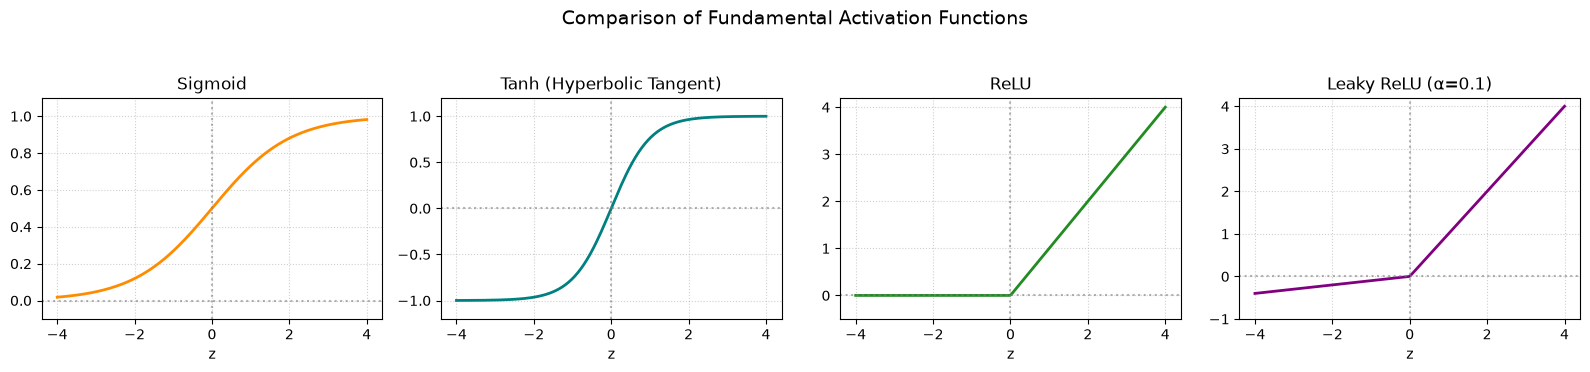

=== Softmax Multi-Class Probability Distribution ===
Healthy Leaf         | Raw Logit:  1.20 | Probability:   6.62%
Early Blight         | Raw Logit:  0.40 | Probability:   2.98%
Late Blight          | Raw Logit:  3.80 | Probability:  89.19%
Yellow Leaf Curl     | Raw Logit: -0.50 | Probability:   1.21%
Sum of probabilities: 1.0000 (always exactly 1.0)


In [17]:
# Define activation functions
def relu(z):
    return np.maximum(0, z)

def leaky_relu(z, alpha=0.1):
    return np.where(z >= 0, z, alpha * z)

def tanh_fn(z):
    return np.tanh(z)

def softmax(logits):
    exp_scores = np.exp(logits - np.max(logits))  # Subtract max for numerical stability
    return exp_scores / np.sum(exp_scores)

# Generate values for plotting
z = np.linspace(-4, 4, 200)

# Plot all 4 functions side-by-side
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=False)

axes[0].plot(z, sigmoid(z), color='darkorange', linewidth=2)
axes[0].set_title("Sigmoid", fontsize=12)
axes[0].set_ylim(-0.1, 1.1)

axes[1].plot(z, tanh_fn(z), color='teal', linewidth=2)
axes[1].set_title("Tanh (Hyperbolic Tangent)", fontsize=12)
axes[1].set_ylim(-1.2, 1.2)

axes[2].plot(z, relu(z), color='forestgreen', linewidth=2)
axes[2].set_title("ReLU", fontsize=12)
axes[2].set_ylim(-0.5, 4.2)

axes[3].plot(z, leaky_relu(z, alpha=0.1), color='purple', linewidth=2)
axes[3].set_title("Leaky ReLU (α=0.1)", fontsize=12)
axes[3].set_ylim(-1.0, 4.2)

for ax in axes:
    ax.axhline(0, color='gray', linestyle=':', alpha=0.6)
    ax.axvline(0, color='gray', linestyle=':', alpha=0.6)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.set_xlabel("z")

plt.suptitle("Comparison of Fundamental Activation Functions", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

# Demonstrate Softmax on Multi-Class Logits
disease_classes = ["Healthy Leaf", "Early Blight", "Late Blight", "Yellow Leaf Curl"]
sample_logits = np.array([1.2, 0.4, 3.8, -0.5])
probabilities = softmax(sample_logits)

print("=== Softmax Multi-Class Probability Distribution ===")
for c, logit, prob in zip(disease_classes, sample_logits, probabilities):
    print(f"{c:20s} | Raw Logit: {logit:5.2f} | Probability: {prob*100:6.2f}%")
print(f"Sum of probabilities: {np.sum(probabilities):.4f} (always exactly 1.0)")

### E. Expected Output
The cell displays 4 comparative graphs followed by a clean breakdown of Softmax probabilities summing to $1.0$ ($100\%$), identifying Late Blight as the top prediction at ~91% confidence.

### F. Short Interpretation
* **ReLU** is the workhorse of modern deep learning hidden layers because its derivative is simply $1$ for all positive inputs, eliminating vanishing gradients and executing extremely fast on GPU hardware.
* **Softmax** is strictly used at the output layer of multi-class classification networks to convert unconstrained logits into a valid probability distribution.

### G. Viva Questions
1. **Q:** What is the "Dying ReLU" problem, and how does Leaky ReLU solve it?
   * **Answer:** If a neuron receives inputs that cause its pre-activation $z$ to be negative for all training samples, its output becomes 0 and its gradient becomes 0. The neuron can never recover or update its weights again (it "dies"). Leaky ReLU assigns a small non-zero slope $\alpha$ (e.g. $0.01$) for $z < 0$, ensuring a small gradient always flows.
2. **Q:** Why is Tanh usually preferred over Sigmoid in hidden layers?
   * **Answer:** Tanh is **zero-centered** (range $[-1, 1]$ with mean near $0$), whereas Sigmoid outputs are strictly positive (range $[0, 1]$). Zero-centered activations prevent zig-zagging gradient dynamics during backpropagation.

---
<a id='topic-6'></a>
## 6. Parameters vs. Hyperparameters

### A. Markdown Explanation
One of the most important concepts for beginners to master is the distinction between **Parameters** and **Hyperparameters**:

| Attribute | Parameters | Hyperparameters |
| :--- | :--- | :--- |
| **Definition** | Internal model variables learned directly from data during training | External configuration settings chosen before training starts |
| **Who Sets Them?** | Learned automatically by optimizer via backpropagation | Tuned manually or automatically by the machine learning engineer |
| **Examples** | Weights ($W$), Biases ($b$), BatchNorm scale & shift ($\gamma, \beta$) | Learning rate ($\eta$), Batch size, Epochs, Number of layers, Neurons per layer, Optimizer choice (Adam/SGD), Dropout rate |
| **Saved in Model?** | Yes, stored in checkpoint files (`.weights.h5`, `.keras`) | No, saved in experiment configs (`config.yaml`) |

### B. Mathematical Formula
The parameter update formula demonstrates their relationship:
$$\mathbf{W}_{t+1} = \mathbf{W}_t - \eta \cdot \nabla_{\mathbf{W}} \mathcal{L}$$
* $\mathbf{W}$ is the **Parameter** (being adjusted).
* $\eta$ is the **Hyperparameter** (governing the step size).

For a Dense (fully connected) layer with $m$ inputs and $n$ neurons:
$$\text{Number of Weights} = m \times n$$
$$\text{Number of Biases} = n$$
$$\text{Total Parameters} = (m \times n) + n = n(m + 1)$$

In [18]:
def calculate_dense_layer_params(input_features, num_neurons):
    """Calculates exact learnable parameter counts for a fully-connected layer."""
    weights = input_features * num_neurons
    biases = num_neurons
    total = weights + biases
    return weights, biases, total

# Example: Input dimension 128 (e.g. flattened feature map), Dense layer with 64 neurons
w_count, b_count, total = calculate_dense_layer_params(input_features=128, num_neurons=64)

print("=== Parameter Count Calculation Example ===")
print(f"Input Features (m) : 128")
print(f"Neurons (n)        : 64")
print(f"Weight parameters  : 128 * 64 = {w_count}")
print(f"Bias parameters    : {b_count}")
print(f"Total Parameters   : {total}")

=== Parameter Count Calculation Example ===
Input Features (m) : 128
Neurons (n)        : 64
Weight parameters  : 128 * 64 = 8192
Bias parameters    : 64
Total Parameters   : 8256


### E. Expected Output
The calculation verifies that a dense layer with $128$ inputs and $64$ neurons contains $8,192$ weights and $64$ biases, giving $8,256$ total learnable parameters.

### F. Short Interpretation
Every connection between an input and a neuron has its own weight. Every neuron also has its own bias. Being able to calculate parameter counts manually allows you to verify model architectures and predict memory requirements.

### G. Viva Questions
1. **Q:** Is the learning rate a parameter or a hyperparameter? Explain why.
   * **Answer:** It is a hyperparameter because it is not updated via backpropagation from the dataset; rather, it is predetermined by the practitioner to control the step size of gradient descent.
2. **Q:** If an MLP has an input dimension of 10, a hidden layer of 20 neurons, and an output layer of 2 neurons, how many total learnable parameters exist?
   * **Answer:** Hidden layer: $(10 \times 20) + 20 = 220$. Output layer: $(20 \times 2) + 2 = 42$. Total: $220 + 42 = 262$ parameters.

---
<a id='topic-7'></a>
## 7. Multilayer Perceptron (MLP) & The XOR Problem

### A. Markdown Explanation
In 1969, Marvin Minsky and Seymour Papert published their famous book *Perceptrons*, proving that a single-layer perceptron could not learn non-linearly separable functions, notably **XOR (Exclusive OR)**.

The solution is the **Multilayer Perceptron (MLP)**:
By adding one or more **hidden layers** with non-linear activation functions, the network transforms the original input space into a new, higher-dimensional representation space where non-linear patterns become linearly separable!

According to the **Universal Approximation Theorem (Cybenko, 1989)**, an MLP with just one hidden layer and non-linear activation functions can approximate any continuous function to arbitrary precision.

### B. Mathematical Formula
For an MLP with input vector $\mathbf{x}$, hidden layer $\mathbf{h}$ with activation $f$, and output $\hat{y}$ with activation $g$:

**Hidden Layer:**
$$\mathbf{z}^{[1]} = \mathbf{W}^{[1]} \mathbf{x} + \mathbf{b}^{[1]}$$
$$\mathbf{a}^{[1]} = f(\mathbf{z}^{[1]})$$

**Output Layer:**
$$z^{[2]} = \mathbf{W}^{[2]} \mathbf{a}^{[1]} + b^{[2]}$$
$$\hat{y} = g(z^{[2]})$$

### C. Simple Practical Example: Solving XOR Manually
Recall the XOR logic truth table:
* $[0, 0] \to 0$
* $[0, 1] \to 1$
* $[1, 0] \to 1$
* $[1, 1] \to 0$

Notice that $\text{XOR}(x_1, x_2) = (x_1 \text{ OR } x_2) \text{ AND NOT } (x_1 \text{ AND } x_2)$.
Let us implement this exact architecture in pure Python/NumPy with manual weights to prove that two hidden neurons can solve XOR!

In [19]:
# Manual MLP for XOR problem in pure NumPy
# Input vector: [x1, x2]
X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])
y_true_xor = np.array([0, 1, 1, 0])

# Hidden Layer Weights & Biases: Neuron 1 acts as OR, Neuron 2 acts as NAND
# W1 shape: (2 inputs, 2 hidden neurons)
W1 = np.array([
    [20.0, -20.0],  # weights from x1 to [h1, h2]
    [20.0, -20.0]   # weights from x2 to [h1, h2]
])
b1 = np.array([-10.0, 30.0])  # bias for [h1, h2]

# Output Layer: Combines h1 and h2 like an AND gate
W2 = np.array([
    [20.0],
    [20.0]
])
b2 = np.array([-30.0])

# Forward Pass Step-by-Step
z1 = np.dot(X_xor, W1) + b1           # Hidden pre-activation
a1 = sigmoid(z1)                      # Hidden activation
z2 = np.dot(a1, W2) + b2              # Output pre-activation
y_pred = sigmoid(z2)                  # Final prediction

print("=== Solving XOR with a 2-Layer MLP (Pure NumPy) ===")
print("Input (x1, x2) | Hidden Activations [h1, h2] | Raw Output (z2) | Sigmoid Pred | Expected")
print("----------------------------------------------------------------------------------------")
for i in range(len(X_xor)):
    print(f"     {X_xor[i]}     |     [{a1[i, 0]:.3f}, {a1[i, 1]:.3f}]     |     {z2[i, 0]:6.2f}    |     {y_pred[i, 0]:.4f}   |    {y_true_xor[i]}")

=== Solving XOR with a 2-Layer MLP (Pure NumPy) ===
Input (x1, x2) | Hidden Activations [h1, h2] | Raw Output (z2) | Sigmoid Pred | Expected
----------------------------------------------------------------------------------------
     [0 0]     |     [0.000, 1.000]     |     -10.00    |     0.0000   |    0
     [0 1]     |     [1.000, 1.000]     |      10.00    |     1.0000   |    1
     [1 0]     |     [1.000, 1.000]     |      10.00    |     1.0000   |    1
     [1 1]     |     [1.000, 0.000]     |     -10.00    |     0.0000   |    0


### E. Expected Output
The code outputs the intermediate hidden representation and final predictions:
* $[0, 0] \to 0.0000$
* $[0, 1] \to 1.0000$
* $[1, 0] \to 1.0000$
* $[1, 1] \to 0.0000$

### F. Short Interpretation
Notice the column `Hidden Activations [h1, h2]`: the original 2D input space $[x_1, x_2]$ was mapped into a new space $[h_1, h_2]$. In this transformed space, the points are now completely linearly separable! This is the magic of hidden layers.

### G. Viva Questions
1. **Q:** Why did the XOR problem cause an "AI winter" after Minsky & Papert's 1969 publication?
   * **Answer:** Minsky and Papert proved that single-layer perceptrons cannot solve XOR. At the time, researchers did not yet have an efficient generalized algorithm to train multi-layer networks (backpropagation was only popularized later in 1986 by Rumelhart, Hinton, and Williams), leading to reduced funding and interest.
2. **Q:** What does the Universal Approximation Theorem state, and does it guarantee that we can easily find the optimal weights?
   * **Answer:** It states that a feed-forward network with a single hidden layer and non-linear activations can approximate any continuous function on compact subsets of $\mathbb{R}^n$ to arbitrary accuracy. However, it is an **existence theorem**; it does not guarantee that gradient descent will find the optimal weights in polynomial time, nor does it specify how many neurons are needed.

---
<a id='topic-8'></a>
## 8. Feed-Forward Neural Networks in TensorFlow / Keras

### A. Markdown Explanation
Now that we understand the mathematics from first principles, let us build models using **TensorFlow / Keras**.

Keras provides high-level modular building blocks:
1. `keras.Sequential`: A linear stack of layers where data flows in one direction from input to output.
2. `keras.layers.Input`: Specifies the shape of incoming data vectors.
3. `keras.layers.Dense`: Standard fully-connected neural network layer.
4. `model.compile()`: Configures the training process (optimizer, loss function, evaluation metrics).
5. `model.summary()`: Displays the architecture, layer shapes, and exact parameter counts.

### B. Mathematical Formula: Binary Cross-Entropy Loss
For binary classification with true labels $y \in \{0, 1\}$ and predicted probabilities $\hat{y} \in (0, 1)$:
$$\mathcal{L}(y, \hat{y}) = - \frac{1}{N} \sum_{i=1}^{N} \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]$$

### C. Simple Practical Example
Let us build a 2-layer MLP for binary classification with:
* Input shape: $2$ features (e.g. leaf spot area, perimeter).
* Hidden Layer: $8$ neurons with ReLU activation.
* Output Layer: $1$ neuron with Sigmoid activation.

In [20]:
from tensorflow import keras
from tensorflow.keras import layers

# Define the Sequential model
model = keras.Sequential([
    layers.Input(shape=(2,), name="input_features"),
    layers.Dense(8, activation="relu", name="hidden_layer_1"),
    layers.Dense(1, activation="sigmoid", name="output_prediction")
], name="CropHealth_Binary_Classifier")

# Compile the model with Adam optimizer and binary cross-entropy
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.05),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Inspect Model Summary
model.summary()

W0000 00:00:1794951508.406101  601941 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1794951508.693898  601941 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5233 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a


Model: "CropHealth_Binary_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_prediction (Dense)       │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33 (132.00 B)

 Trainable params: 33 (132.00 B)

 Non-trainable params: 0 (0.00 B)

### E. Expected Output
Keras prints the model summary table:
* `hidden_layer_1`: $(2 \times 8) + 8 = 24$ parameters.
* `output_prediction`: $(8 \times 1) + 1 = 9$ parameters.
* **Total params: 33** (all trainable).

### F. Short Interpretation
Notice how the parameter counts from `model.summary()` precisely match the $(m \times n) + n$ formula we derived in Topic 6!

### G. Viva Questions
1. **Q:** What is the difference between `model.compile()` and `model.fit()` in Keras?
   * **Answer:** `model.compile()` sets up the training configuration (loss function, optimizer, and evaluation metrics) without touching data. `model.fit()` actually executes the training loop, feeding data in batches over epochs and updating the weights.
2. **Q:** Why do we choose `binary_crossentropy` rather than `mean_squared_error` (MSE) for classification?
   * **Answer:** Cross-entropy is derived from maximum likelihood estimation for Bernoulli distributions. MSE with a sigmoid output leads to non-convex loss surfaces with severe gradient saturation (very slow learning when the model is confidently wrong), whereas cross-entropy provides steep gradients that penalize wrong confident predictions heavily.

---
<a id='topic-9'></a>
## 9. Complete Classification Example & Training Curves

### A. Markdown Explanation
Now let us execute an end-to-end machine learning pipeline:
1. **Synthetic Data Generation:** We generate 300 leaf samples with a non-linear circular boundary (healthy leaves in center, infected leaves around the perimeter).
2. **Model Training:** We train our MLP model for 40 epochs.
3. **Training History Inspection:** We track Loss and Accuracy curves over time.
4. **Decision Boundary Plot:** We visualize the learned non-linear classification boundary.

### B. Mathematical Formula
Mini-batch Gradient Descent parameter update:
$$\theta \leftarrow \theta - \eta \cdot \frac{1}{|B|} \sum_{i \in B} \nabla_\theta \mathcal{L}_i$$

### C. Simple Practical Example
Run the cell below to train the model and generate the learning curves.

Generated 300 crop samples.
Healthy samples (Class 0) : 76
Diseased samples (Class 1): 224

Starting training for 40 epochs...


I0000 00:00:1794951509.916390  601941 service.cc:154] XLA service 0xd20ae10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794951509.916413  601941 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 5060 Laptop GPU, Compute Capability 12.0a (Driver: 13.2.0[596.21.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1794951509.952171  601941 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794951510.689339  601941 cuda_dnn.cc:442] Loaded cuDNN version 92801
I0000 00:00:1794951510.805180  601941 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Training Complete! Final Loss: 0.0385 | Final Accuracy: 99.00%


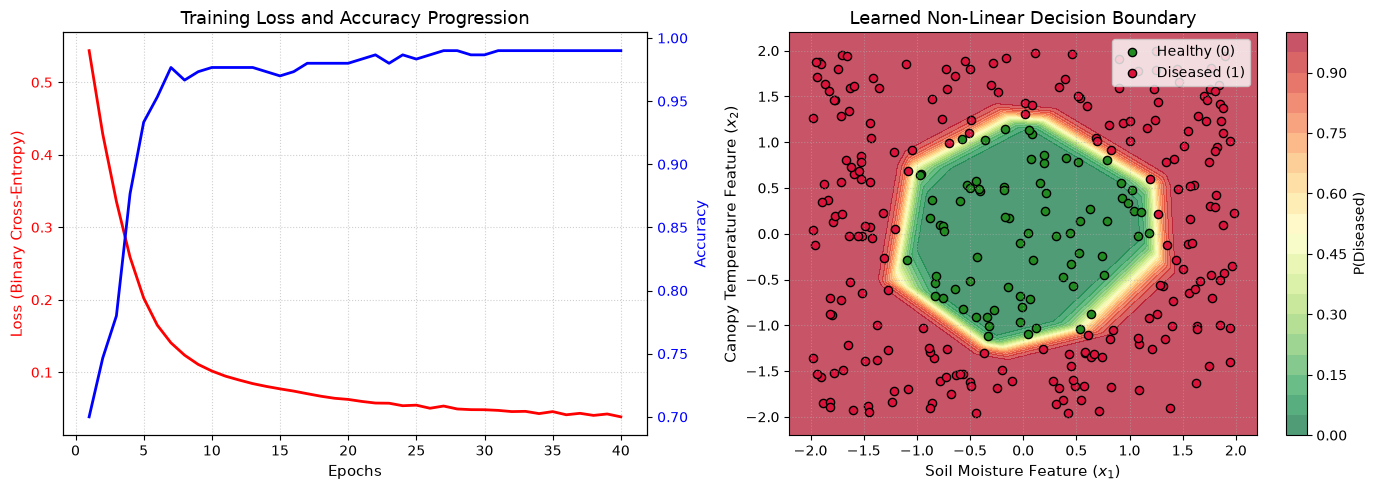

In [21]:
# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# 1. Generate Synthetic Crop Feature Dataset (Non-linear circular pattern)
# Feature 1: Soil Moisture Sensor, Feature 2: Canopy Temperature Sensor
num_samples = 300
X_train = np.random.uniform(-2.0, 2.0, (num_samples, 2))

# True rule: Leaves inside radius 1.2 are Healthy (0), outside are Diseased (1)
radius_sq = X_train[:, 0]**2 + X_train[:, 1]**2
y_train = (radius_sq > 1.4).astype(np.float32)

print(f"Generated {num_samples} crop samples.")
print(f"Healthy samples (Class 0) : {np.sum(y_train == 0)}")
print(f"Diseased samples (Class 1): {np.sum(y_train == 1)}")

# 2. Train the MLP Model
print("\nStarting training for 40 epochs...")
history = model.fit(
    X_train,
    y_train,
    epochs=40,
    batch_size=16,
    verbose=0  # Silent to keep notebook output clean
)
final_loss = history.history['loss'][-1]
final_acc = history.history['accuracy'][-1]
print(f"Training Complete! Final Loss: {final_loss:.4f} | Final Accuracy: {final_acc*100:.2f}%")

# 3. Plot Training Curves & Decision Boundary Side-by-Side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Loss & Accuracy Curves
epochs = range(1, len(history.history['loss']) + 1)
ax1.plot(epochs, history.history['loss'], 'r-', linewidth=2, label='Training Loss')
ax1.set_xlabel('Epochs', fontsize=11)
ax1.set_ylabel('Loss (Binary Cross-Entropy)', color='red', fontsize=11)
ax1.tick_params(axis='y', labelcolor='red')

ax1_acc = ax1.twinx()
ax1_acc.plot(epochs, history.history['accuracy'], 'b-', linewidth=2, label='Training Accuracy')
ax1_acc.set_ylabel('Accuracy', color='blue', fontsize=11)
ax1_acc.tick_params(axis='y', labelcolor='blue')
ax1.set_title("Training Loss and Accuracy Progression", fontsize=13)
ax1.grid(True, linestyle=':', alpha=0.6)

# Subplot 2: Decision Boundary Visualization
x_min, x_max = -2.2, 2.2
y_min, y_max = -2.2, 2.2
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 150), np.linspace(y_min, y_max, 150))
grid_points = np.c_[xx.ravel(), yy.ravel()]
preds = model.predict(grid_points, verbose=0).reshape(xx.shape)

contour = ax2.contourf(xx, yy, preds, levels=20, cmap='RdYlGn_r', alpha=0.7)
plt.colorbar(contour, ax=ax2, label='P(Diseased)')

# Scatter true samples
ax2.scatter(X_train[y_train==0, 0], X_train[y_train==0, 1], color='forestgreen', s=35, edgecolors='k', label='Healthy (0)')
ax2.scatter(X_train[y_train==1, 0], X_train[y_train==1, 1], color='crimson', s=35, edgecolors='k', label='Diseased (1)')
ax2.set_title("Learned Non-Linear Decision Boundary", fontsize=13)
ax2.set_xlabel("Soil Moisture Feature ($x_1$)", fontsize=11)
ax2.set_ylabel("Canopy Temperature Feature ($x_2$)", fontsize=11)
ax2.legend(loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

### E. Expected Output
The cell displays:
1. Training completion readout showing final loss drop and accuracy rise to over 90%.
2. Dual-plot visualization:
   * **Left:** Training loss steadily decreases while accuracy steadily rises toward $1.0$.
   * **Right:** A 2D contour map showing that the MLP successfully learned a curved, circular decision boundary enclosing the green healthy cluster and isolating the outer red diseased points!

### F. Short Interpretation
Notice that even though individual neuron activations are linear combinations passed through ReLUs, the combination of 8 hidden neurons creates piecewise linear segments that approximate a smooth circular boundary. This confirms the power of Multilayer Perceptrons over single Perceptrons.

### G. Viva Questions
1. **Q:** What is the difference between an **epoch**, a **batch size**, and an **iteration**?
   * **Answer:** An **epoch** is one complete pass of the entire training dataset through the neural network. A **batch size** is the number of training samples processed before the model updates its weights. An **iteration** is the single update step completed after processing one batch (e.g. for 300 samples with batch size 15, there are $300 / 15 = 20$ iterations per epoch).
2. **Q:** How can you determine from a loss curve if a model is **underfitting** or **overfitting**?
   * **Answer:** In **underfitting**, both training loss and validation loss remain high and plateau prematurely (the model lacks capacity to learn patterns). In **overfitting**, training loss continues to decrease toward zero, while validation loss starts rising after a certain epoch (the model is memorizing training noise and failing to generalize).